# Diagnóstico espacial — autocorrelación de residuos y *spatial lag*
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Marco teórico

La **primera ley de la geografía** (Tobler, 1970) resume una regularidad conocida del mercado
inmobiliario: *"todo se relaciona con todo, pero lo cercano más que lo lejano"*. Si un modelo de precios
capturó bien la estructura espacial, sus **errores** deberían distribuirse **sin patrón geográfico**; si,
en cambio, los residuos de propiedades vecinas se parecen entre sí (positivos junto a positivos,
negativos junto a negativos), quedaría **estructura espacial no explicada** —un indicio de que conviene
modelar el espacio de forma explícita— (LeSage & Pace, 2009; Anselin, 1988).

Para cuantificarlo usamos el **I de Moran** (Moran, 1950), la medida estándar de **autocorrelación
espacial**. Es, en esencia, la correlación entre el valor de cada punto y el **promedio de sus vecinos**;
toma valores en torno a 0 bajo aleatoriedad espacial, positivos ante agrupamiento (*clustering*) y
negativos ante dispersión. Su significancia se evalúa por **permutaciones** (se reordena al azar la
variable sobre las ubicaciones y se compara el I observado con la distribución nula).

Este notebook responde dos preguntas:

- **RQ3.** ¿Los residuos del modelo presentan autocorrelación espacial? Comparamos el **hedónico** y el
  **LightGBM** (modelo final), para ver si el modelo flexible deja **menos** estructura espacial sin
  explicar.
- **RQ4.** Si la hay, ¿un término de **rezago espacial** (*spatial lag*: el precio promedio de los
  vecinos) la **reduce** y mejora la predicción? El rezago se construye **por fold, solo con datos de
  train**, para no incurrir en fuga (Gyger et al., 2026).

## Metodología

- **Residuos:** predicciones **fuera de fold** (OOF) sobre el escenario S4, con las mismas particiones
  group-aware. Para el hedónico se usa OLS; para LightGBM, la configuración hallada en el notebook 04.
- **Unidad espacial:** se **agrega el residuo promedio por propiedad/edificio** (`building_cluster_id`) y
  se usa su **centroide** (lat/lon medias). Así, las republicaciones —coordenadas repetidas— no inflan
  artificialmente la autocorrelación.
- **Pesos espaciales:** **KNN** con $k=8$ vecinos, fila-estandarizados (cada vecino pesa $1/k$).
- **I de Moran + permutaciones** (999) para la inferencia; se acompaña con el *Moran scatterplot*.
- **Rezago espacial (RQ4):** para cada observación, el **log-precio promedio de sus $k$ vecinos de
  train**; se calcula **dentro de cada fold** (vecinos buscados solo en el train del fold), se agrega
  como variable y se reajusta LightGBM para medir el cambio en test y en la autocorrelación de residuos.

In [1]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import mean_squared_error, r2_score
from lightgbm import LGBMRegressor

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT, MOR = "#2c6e91", "#c0562b", "#3a8f5e", "#7b5ea7"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5, "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
lat = pd.to_numeric(df["eda_latitud"], errors="coerce").values
lon = pd.to_numeric(df["eda_longitud"], errors="coerce").values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
cols_s4 = [c for c in S1+S2+S3 if c in df.columns] + feat_cols
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}
SEED, K = 42, 8
# configuración de LightGBM hallada en el notebook 04 (búsqueda anidada)
LGBM = dict(n_estimators=1105, learning_rate=0.0117, num_leaves=16, max_depth=10, min_child_samples=34,
            subsample=0.7217, colsample_bytree=0.8604, reg_alpha=0.006, reg_lambda=0.006,
            subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1)
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} edificios · KNN k={K}")

Matriz: 4,765 avisos · 1,377 edificios · KNN k=8


## Predicciones OOF, agregación por edificio e I de Moran

In [2]:
def prep_ohe(cols, escala):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    num_pipe = Pipeline([("i",SimpleImputer(strategy="median"))] + ([("s",StandardScaler())] if escala else []))
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=(not escala) and False))]), cat),
        ("bin","passthrough" if not escala else SimpleImputer(strategy="most_frequent"), binz),
        ("num", num_pipe, num)], remainder="drop")

def oof_pred(estimador_fn, cols, extra=None):
    "OOF con GroupKFold(5). extra(tr,te)->(col_tr,col_te) agrega una columna calculada por fold (p.ej. spatial lag)."
    gkf=GroupKFold(5); oof=np.full(len(y),np.nan)
    for tr,te in gkf.split(df,y,groups):
        Xtr, Xte = df.iloc[tr][cols].copy(), df.iloc[te][cols].copy()
        if extra is not None:
            ctr,cte = extra(tr,te); Xtr["fe_spatial_lag"]=ctr; Xte["fe_spatial_lag"]=cte
        est=estimador_fn().fit(Xtr,y[tr]); oof[te]=est.predict(Xte)
    return oof

# residuos OOF de los dos modelos sobre S4
oof_ols = oof_pred(lambda: Pipeline([("p",prep_ohe(cols_s4,True)),("m",LinearRegression())]), cols_s4)
oof_lgb = oof_pred(lambda: Pipeline([("p",prep_ohe(cols_s4,False)),("m",LGBMRegressor(**LGBM))]), cols_s4)
resid = {"Hedónico (OLS)": y-oof_ols, "LightGBM": y-oof_lgb}
print("R²(log) OOF — OLS:", round(r2_score(y,oof_ols),3), "· LightGBM:", round(r2_score(y,oof_lgb),3))

def agregar_por_edificio(r):
    d=pd.DataFrame({"g":groups,"lat":lat,"lon":lon,"r":r}).dropna()
    a=d.groupby("g").agg(lat=("lat","mean"),lon=("lon","mean"),r=("r","mean")).reset_index()
    return a

def moran(coords, z, k=K, n_perm=999, seed=SEED):
    z=z-z.mean()
    nn=NearestNeighbors(n_neighbors=k+1).fit(coords)
    idx=nn.kneighbors(coords, return_distance=False)[:,1:]   # k vecinos (excluye self)
    Wz=z[idx].mean(axis=1)                                   # promedio de vecinos (fila-estandarizado)
    I=float((z*Wz).sum()/(z*z).sum())
    rng=np.random.default_rng(seed); perm=np.empty(n_perm)
    for b in range(n_perm):
        zp=rng.permutation(z); perm[b]=(zp*zp[idx].mean(axis=1)).sum()/(zp*zp).sum()
    p=(np.sum(perm>=I)+1)/(n_perm+1)
    return I, p, z, Wz
print("Utilitarios definidos.")

R²(log) OOF — OLS: 0.865 · LightGBM: 0.902
Utilitarios definidos.


## Autocorrelación espacial del precio (PI3)

Antes de evaluar los residuos, verificamos que el **propio precio** presenta estructura espacial, con la
misma unidad territorial (edificio/cuadra) y matriz de vecinos (KNN, k=8). Esto da la secuencia completa de
PI3: Moran del precio → Moran de residuos OLS → Moran de residuos LightGBM.

In [3]:
pm2 = pd.to_numeric(df['eda_precio_usd'],errors='coerce').values / pd.to_numeric(df['eda_superficie_total_m2'],errors='coerce').values
for nombre, val in [('log-precio', y), ('log precio/m2', np.log(pm2))]:
    a = agregar_por_edificio(val)
    I,p,_,_ = moran(a[['lat','lon']].values, a['r'].values)
    print(f"Moran {nombre}: I={I:.3f}  p={p:.3f}  (n_edificios={len(a)})")

Moran log-precio: I=0.306  p=0.001  (n_edificios=1377)
Moran log precio/m2: I=0.284  p=0.001  (n_edificios=1359)


## 1. Autocorrelación espacial de los residuos (RQ3)

Calculamos el I de Moran sobre el **residuo promedio por edificio** de cada modelo, con inferencia por
permutaciones, y lo visualizamos con el *Moran scatterplot* (residuo vs. promedio de vecinos; la
pendiente es el propio I).

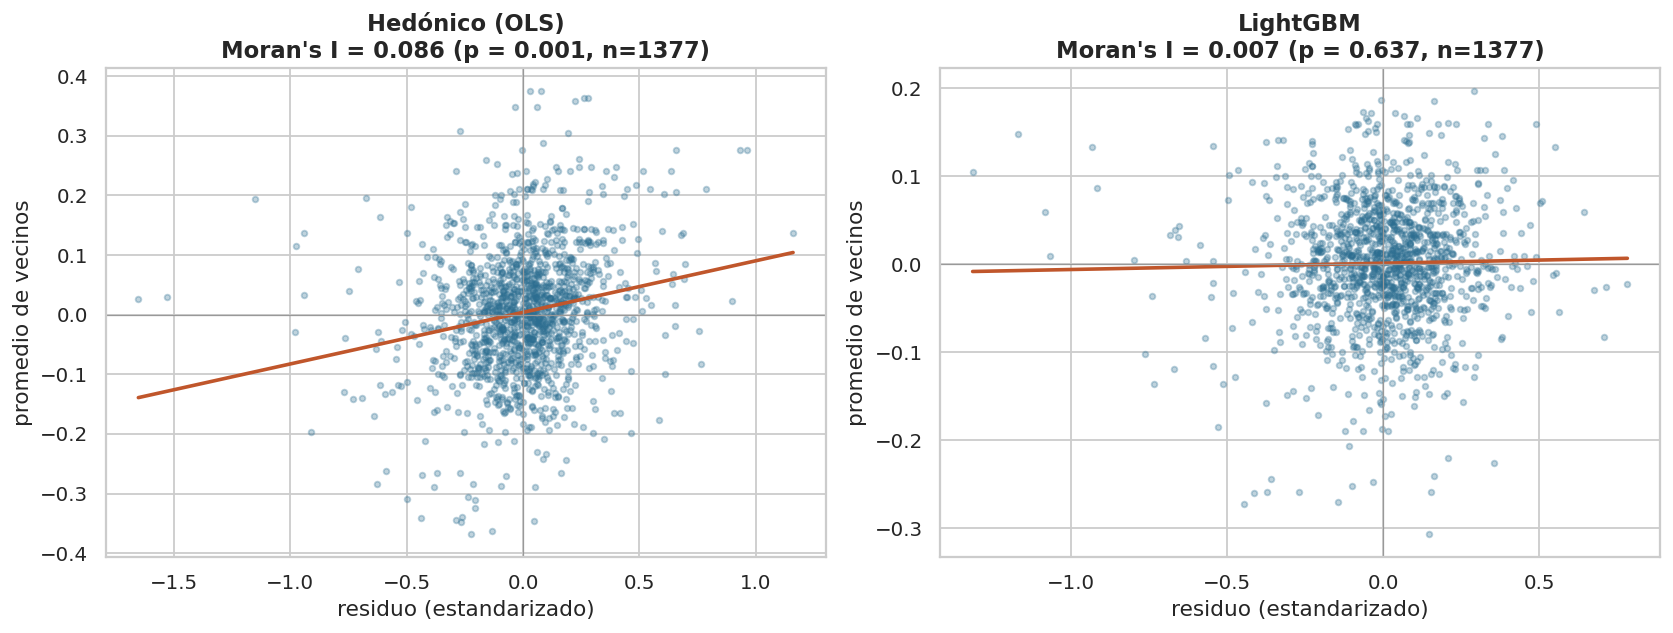

,Moran_I,p_valor,n_edificios
Hedónico (OLS),0.086,0.001,1377.0
LightGBM,0.007,0.637,1377.0


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5)); res_moran={}
for ax,(nombre,r) in zip(axs, resid.items()):
    a=agregar_por_edificio(r); coords=a[["lat","lon"]].values
    I,p,z,Wz=moran(coords, a["r"].values)
    res_moran[nombre]=dict(I=I,p=p,n=len(a))
    ax.scatter(z,Wz,s=10,alpha=.3,color=PAL)
    m,b=np.polyfit(z,Wz,1); xs=np.linspace(z.min(),z.max(),50)
    ax.plot(xs,m*xs+b,color=PAL2,lw=2); ax.axhline(0,color="0.6",lw=.7); ax.axvline(0,color="0.6",lw=.7)
    ax.set(title=f"{nombre}\nMoran's I = {I:.3f} (p = {p:.3f}, n={len(a)})",
           xlabel="residuo (estandarizado)", ylabel="promedio de vecinos")
plt.show()
display(pd.DataFrame(res_moran).T.rename(columns={"I":"Moran_I","p":"p_valor","n":"n_edificios"}).round({"Moran_I":3,"p_valor":3}))

**Lectura.** El contraste es marcado. Los residuos del **hedónico** presentan autocorrelación
espacial **positiva y significativa** (I de Moran = 0,086; p = 0,001): errores de edificios vecinos
tienden a parecerse, lo que señalaría estructura espacial no capturada por la forma lineal. Los residuos
del **LightGBM**, en cambio, no muestran autocorrelación apreciable (I = 0,007; p = 0,64): serían, a los
fines prácticos, **espacialmente aleatorios**. Esto sería consistente con que el modelo flexible
**absorbe** la estructura espacial —vía barrio, coordenadas, distancias e interacciones no lineales— que
el lineal deja en el residuo. El *Moran scatterplot* refleja lo mismo: pendiente marcada en el hedónico y
casi plana en LightGBM.

## 2. Rezago espacial como remedio (RQ4)

Agregamos como variable el **log-precio promedio de los $k$ vecinos**, calculado **por fold** buscando
vecinos **solo en el train** (para cada punto de test, sus vecinos son de train; para cada punto de
train, sus otros vecinos de train). Reajustamos LightGBM con esta variable y comparamos test y
autocorrelación de residuos contra el modelo sin rezago.

In [5]:
def lag_por_fold(tr, te):
    ct=np.c_[lat,lon]
    nn=NearestNeighbors(n_neighbors=K+1).fit(ct[tr]); ptr=y[tr]
    itr=nn.kneighbors(ct[tr], return_distance=False)[:,1:]           # vecinos de train (excluye self)
    ite=nn.kneighbors(ct[te], n_neighbors=K, return_distance=False)  # vecinos de train para test
    return ptr[itr].mean(axis=1), ptr[ite].mean(axis=1)

oof_lag = oof_pred(lambda: Pipeline([("p",prep_ohe(cols_s4+["fe_spatial_lag"],False)),("m",LGBMRegressor(**LGBM))]),
                   cols_s4, extra=lag_por_fold)

def met(oof):
    ytu,ypu=np.expm1(y),np.expm1(oof)
    return r2_score(y,oof), np.sqrt(mean_squared_error(ytu,ypu)), np.mean(np.abs((ytu-ypu)/ytu))*100

r0=met(oof_lgb); r1=met(oof_lag)
a0=agregar_por_edificio(y-oof_lgb); a1=agregar_por_edificio(y-oof_lag)
I0,p0,_,_=moran(a0[["lat","lon"]].values, a0["r"].values); I1,p1,_,_=moran(a1[["lat","lon"]].values, a1["r"].values)
tabla=pd.DataFrame({"LightGBM (sin rezago)":{"R2_test":r0[0],"RMSE_test":r0[1],"MAPE_test":r0[2],"Moran_I_resid":I0,"p":p0},
                    "LightGBM + spatial lag":{"R2_test":r1[0],"RMSE_test":r1[1],"MAPE_test":r1[2],"Moran_I_resid":I1,"p":p1}}).T
display(tabla.round({"R2_test":3,"RMSE_test":0,"MAPE_test":1,"Moran_I_resid":3,"p":3}))

,R2_test,RMSE_test,MAPE_test,Moran_I_resid,p
LightGBM (sin rezago),0.902,39667.0,16.6,0.007,0.637
LightGBM + spatial lag,0.897,40902.0,17.1,-0.014,0.988


**Lectura.** Al agregar el rezago espacial, el desempeño de LightGBM **no mejora** —de hecho baja
levemente (R² 0,902 → 0,897; RMSE ~USD 39,7k → ~USD 40,9k)— y el I de Moran de los residuos pasa de 0,007
a −0,014 (ambos no significativos). Es coherente con el diagnóstico de RQ3: como el LightGBM **ya no
dejaba autocorrelación** en sus residuos, no habría estructura espacial remanente que el rezago pueda
aprovechar, y su incorporación solo agregaría ruido. Para el modelo final, entonces, el rezago espacial
**no resultaría necesario**: la localización ya estaría suficientemente representada por barrio,
coordenadas y distancias.

## 3. Conclusiones

- **RQ3.** Los residuos del **hedónico** exhiben autocorrelación espacial positiva y significativa
  (I = 0,086; p = 0,001), mientras que los del **LightGBM** no (I = 0,007; p = 0,64). El modelo flexible
  absorbería la estructura espacial que el lineal deja sin explicar.
- **RQ4.** Un término de **rezago espacial** (KNN, por fold, sin fuga) no mejora al LightGBM
  (R² 0,902 → 0,897) y deja la autocorrelación residual en torno a cero. Es lo esperable, dado que no
  había estructura espacial remanente que capturar: para el modelo final, el rezago no aportaría.
- **Lectura conjunta.** La combinación de barrio, coordenadas y distancias, sumada a la flexibilidad del
  *boosting*, resultaría suficiente para dar cuenta de la dimensión espacial del precio en este distrito;
  un término espacial explícito estaría más justificado para el modelo **lineal** que para el elegido. Con
  esto cierra el diagnóstico espacial; sigue la **interpretabilidad** ampliada (SHAP; RQ5).

## Referencias

**Libros**

- LeSage, J., & Pace, R. K. (2009). *Introduction to Spatial Econometrics*. Chapman & Hall/CRC.
- Anselin, L. (1988). *Spatial Econometrics: Methods and Models*. Kluwer.

**Artículos**

- Moran, P. A. P. (1950). Notes on continuous stochastic phenomena. *Biometrika, 37*(1/2), 17–23.
- Tobler, W. (1970). A computer movie simulating urban growth in the Detroit region. *Economic Geography, 46*, 234–240.
- Gyger et al. (2026). Explainable spatial machine learning for hedonic real estate modeling. *Real Estate Economics*.